# Loan Approval Prediction: End-to-End EDA & Machine Learning
**Objective:** To analyze applicant demographics, financial stability, and credit history to predict whether a home loan application will be approved (`Y`) or rejected (`N`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset and check its dimensions
df = pd.read_csv(r"c:\Users\hp\Downloads\archive (10)\train_u6lujuX_CVtuZ9i.csv")
df.shape

(614, 13)

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [6]:
# Check missing values in descending order
df.isnull().sum().sort_values(ascending=False)

Credit_History       50
Self_Employed        32
LoanAmount           22
Dependents           15
Loan_Amount_Term     14
Gender               13
Married               3
Education             0
Loan_ID               0
CoapplicantIncome     0
ApplicantIncome       0
Property_Area         0
Loan_Status           0
dtype: int64

In [7]:
df['Credit_History'].unique()

array([ 1.,  0., nan])

In [8]:
df['Dependents'].unique()

<ArrowStringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str

 Fill categorical missing values with mode and numerical with median/mean

In [9]:
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

In [10]:
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])

In [11]:
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

In [12]:
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])

In [13]:
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mean())

In [14]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [15]:
df['Married'] = df['Married'].fillna(df['Married'].mode()[0])

In [16]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [17]:
# Drop Loan_ID as it is a unique identifier with no predictive value
df = df.drop(columns=['Loan_ID'])

In [18]:
# Standardize '3+' to '3' in Dependents column
df['Dependents'] = df['Dependents'].replace('3+', '3')

In [19]:
df['Loan_Status'].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

Insight: Out of 614 applications, 422 (~69%) were approved and 192 (~31%) were rejected, showing a moderate class imbalance.

<Axes: xlabel='Credit_History', ylabel='count'>

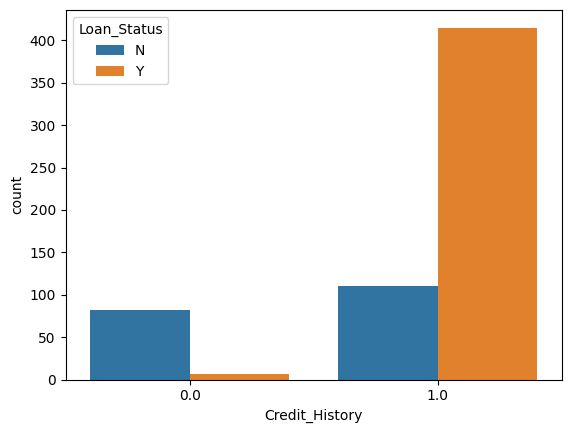

In [20]:
sns.countplot(x='Credit_History',hue='Loan_Status',data=df)

Insight: Credit_History is the strongest factor. Applicants with a good credit history (1.0) have a much higher approval rate than those with a poor history (0.0).

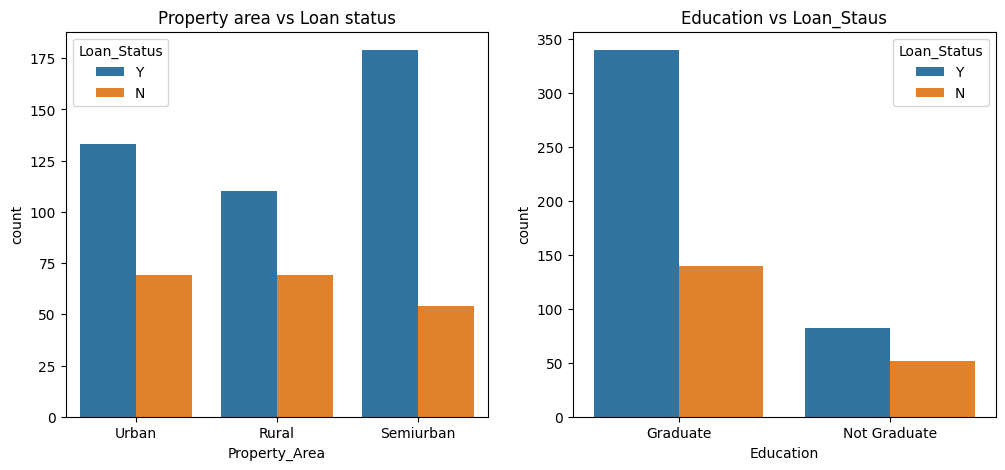

In [21]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.countplot(x='Property_Area',hue='Loan_Status',data=df)
plt.title('Property area vs Loan status')

plt.subplot(1,2,2)
sns.countplot(x='Education',hue='Loan_Status',data=df)
plt.title("Education vs Loan_Staus")
plt.show()



Insight: Applicants from Semiurban areas and Graduates have higher loan approval rates compared to Rural/Urban areas and Non-Graduates.

<Axes: xlabel='ApplicantIncome', ylabel='Count'>

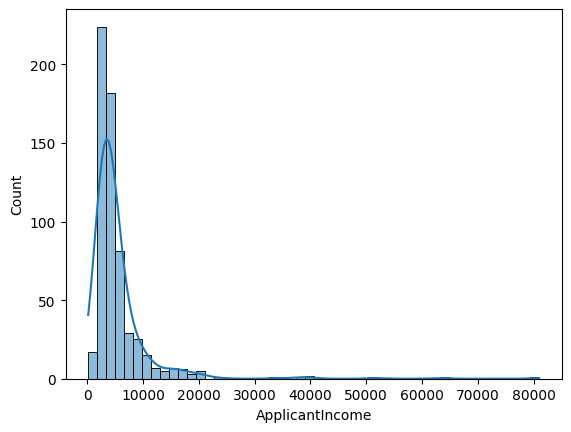

In [22]:
sns.histplot(x='ApplicantIncome',kde=True,data=df)

Insight: ApplicantIncome is heavily right-skewed, with most applicants earning between 2,000 and 6,000 and a few high-income outliers up to 81,000.

<Axes: xlabel='ApplicantIncome', ylabel='LoanAmount'>

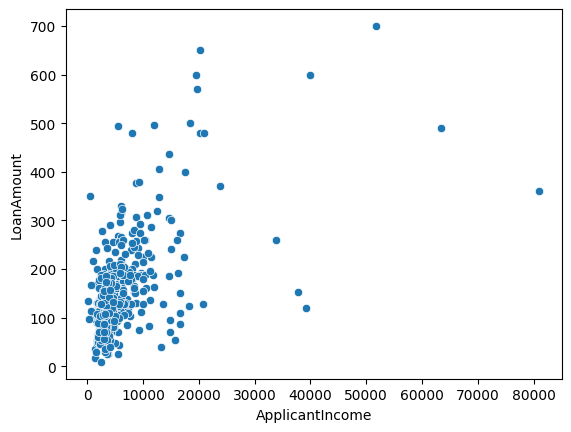

In [23]:
sns.scatterplot(x='ApplicantIncome',y='LoanAmount',data=df)

Insight: There is a positive correlation between ApplicantIncome and LoanAmount for most applicants, though a few high-income individuals requested relatively small loans.

In [24]:
# Encode target variable (Y=1, N=0) and apply One-Hot Encoding on categorical features
df['Loan_Status']=df['Loan_Status'].map({'Y':1,'N':0})

In [25]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,1,True,False,False,False,False,False,False,False,True
1,4583,1508.0,128.0,360.0,1.0,0,True,True,True,False,False,False,False,False,False
2,3000,0.0,66.0,360.0,1.0,1,True,True,False,False,False,False,True,False,True
3,2583,2358.0,120.0,360.0,1.0,1,True,True,False,False,False,True,False,False,True
4,6000,0.0,141.0,360.0,1.0,1,True,False,False,False,False,False,False,False,True


In [26]:
# Split data (80-20) and apply StandardScaler to prevent data leakage
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# 1. Saare True/False (bool) columns ko 1 aur 0 (int) mein badal dein
df_encoded = df_encoded.astype(int)

# 2. Dobara X aur y banayein aur split karein
X = df_encoded.drop(columns=['Loan_Status'])
y = df_encoded['Loan_Status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Ab StandardScaler chalayein
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [27]:
 # Train Logistic Regression model and evaluate test accuracy
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train_scaled, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [28]:
y_pred = model.predict(X_test_scaled)

In [29]:
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred) * 100)


Accuracy: 78.86178861788618


Conclusion: The Logistic Regression model achieved a test accuracy of 78.86%, establishing a strong baseline for loan approval prediction.

In [30]:
import pickle

# Save the trained Logistic Regression model
pickle.dump(model, open('loan_model.pkl', 'wb'))

# Save the fitted StandardScaler to preprocess new user inputs
pickle.dump(scaler, open('loan_scaler.pkl', 'wb'))

# Save the exact list and order of feature columns
pickle.dump(X.columns.tolist(), open('loan_columns.pkl', 'wb'))

print("Model, scaler, and columns saved successfully!")


Model, scaler, and columns saved successfully!
